# 01 - Data Cleaning and EDA
**Goal:** understand the data before modelling. We check quality, fix the known `TotalCharges` issue, and find which customer
characteristics go together with churn. **Why:** every modelling decision later (features, imbalance handling, leakage checks)
depends on what we learn here.

In [ ]:
import sys, json, warnings
sys.path.insert(0, "..")            # so `import src...` works from the notebooks/ folder
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200)
from src.config import REPORTS_DIR, FIG_DIR
from src.data import load_clean
from src.features import add_features
from src import plots

## 1. Raw data and quality checks

In [ ]:
raw = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("shape:", raw.shape)
print("duplicate customerIDs:", raw.customerID.duplicated().sum(), "| missing values:", raw.isna().sum().sum())
print("TotalCharges dtype:", raw.TotalCharges.dtype, "(should be numeric - it is text!)")
blank = raw[raw.TotalCharges.str.strip() == ""]
print("blank TotalCharges:", len(blank), "| their tenure values:", blank.tenure.unique())
raw.head()

shape: (7043, 21)
duplicate customerIDs: 0 | missing values: 0
TotalCharges dtype: str (should be numeric - it is text!)
blank TotalCharges: 11 | their tenure values: [0]


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


**Finding:** the 11 blank `TotalCharges` all have `tenure = 0` (brand-new customers with nothing billed yet), so filling with **0** is the logical choice. `load_clean()` does this and asserts the assumption.

In [ ]:
df = load_clean()
df.dtypes.value_counts()

str        16
int64       3
float64     2
Name: count, dtype: int64

## 2. Target balance

In [ ]:
print(df.Churn.value_counts())
print(f"churn rate = {df.Churn.mean():.1%}  -> imbalanced (about 1 in 4). Accuracy alone would be misleading: predicting 'nobody churns' is already 73.5% accurate.")

Churn
0    5174
1    1869
Name: count, dtype: int64
churn rate = 26.5%  -> imbalanced (about 1 in 4). Accuracy alone would be misleading: predicting 'nobody churns' is already 73.5% accurate.


## 3. What separates churners from stayers?

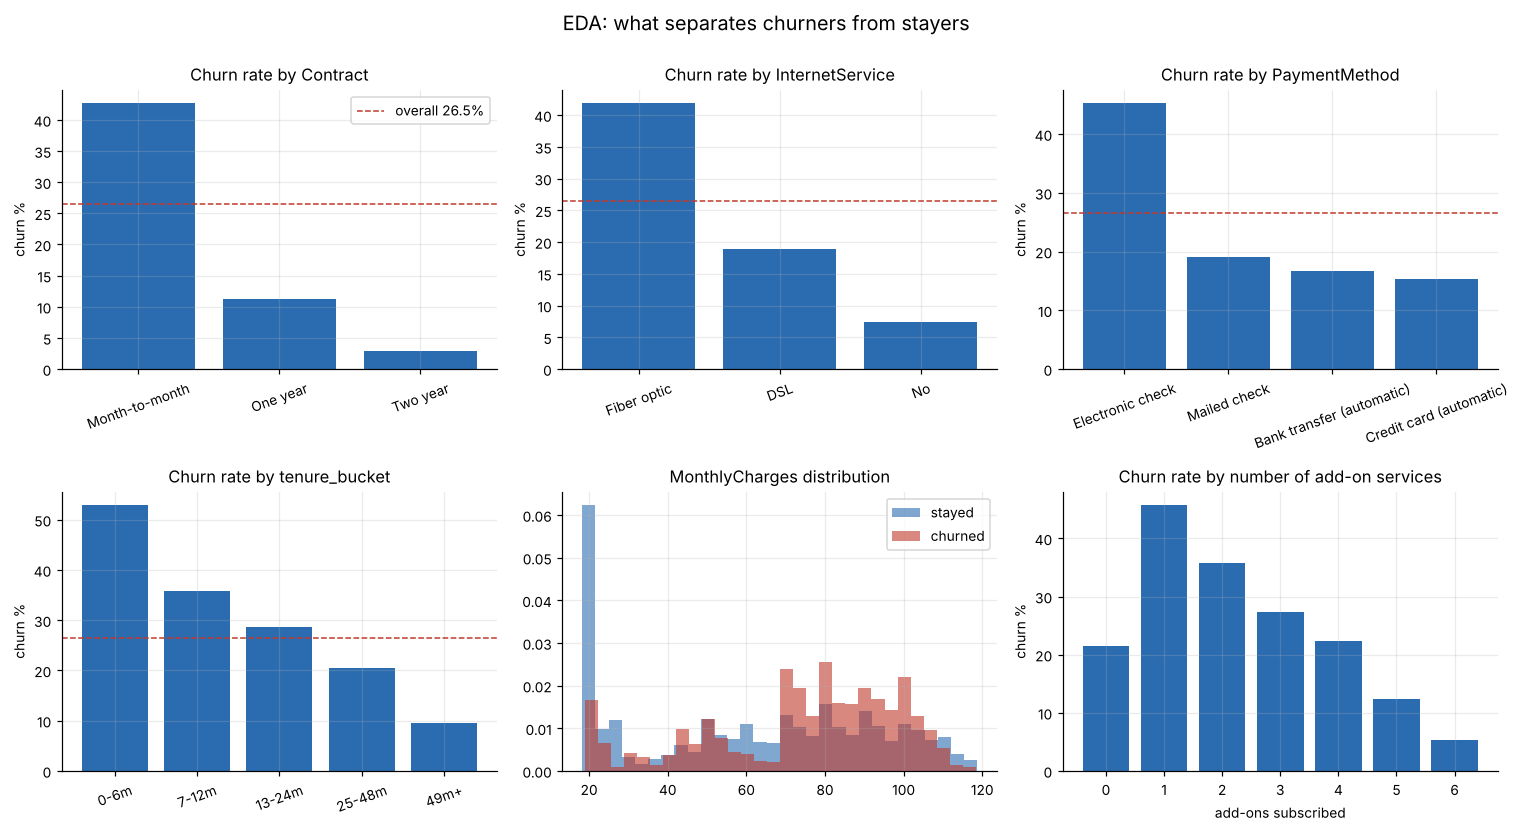

In [ ]:
plots.eda_figures(df); display(Image(FIG_DIR / 'eda_overview.png'))

In [ ]:
d = add_features(df)
for col in ["Contract", "InternetService", "PaymentMethod", "tenure_bucket"]:
    display(d.groupby(col).Churn.agg(churn_rate="mean", customers="size").round(3).sort_values("churn_rate", ascending=False))

,churn_rate,customers
Contract,,
Month-to-month,0.427,3875
One year,0.113,1473
Two year,0.028,1695


,churn_rate,customers
InternetService,,
Fiber optic,0.419,3096
DSL,0.190,2421
No,0.074,1526


,churn_rate,customers
PaymentMethod,,
Electronic check,0.453,2365
Mailed check,0.191,1612
Bank transfer (automatic),0.167,1544
Credit card (automatic),0.152,1522


,churn_rate,customers
tenure_bucket,,
0-6m,0.529,1481
7-12m,0.359,705
13-24m,0.287,1024
25-48m,0.204,1594
49m+,0.095,2239


**Key takeaways (checked against the tables above)**
* **Contract is the strongest signal:** month-to-month customers churn about 43%, one-year about 11%, two-year about 3%.
* **New customers leave:** 0-6 months tenure churn about 53%; 49+ months only about 10%.
* **Fiber optic** customers churn about 42% (DSL 19%, no internet 7%) - likely price/competition related, but the data cannot tell us why.
* **Electronic check** payers churn about 45%, vs about 15-19% for the other payment methods.
* More add-on services (security, backup, support...) goes with **lower** churn.

## 4. Numeric relationships with churn

In [ ]:
d[["tenure", "MonthlyCharges", "TotalCharges", "n_addon_services", "avg_monthly_spend", "charge_gap", "Churn"]].corr()["Churn"].round(3).drop("Churn")

tenure              -0.352
MonthlyCharges       0.193
TotalCharges        -0.198
n_addon_services    -0.088
avg_monthly_spend    0.193
charge_gap           0.002
Name: Churn, dtype: float64

`tenure` is the strongest numeric signal (negative: longer customers stay). `TotalCharges` is mostly `tenure x MonthlyCharges`, so it is highly correlated with tenure - we group them together when explaining predictions.

## 5. Feature engineering (what the model will see)

In [ ]:
d[["tenure", "tenure_bucket", "MonthlyCharges", "TotalCharges", "avg_monthly_spend", "charge_gap", "n_addon_services",
   "is_autopay", "has_protection", "has_family"]].head()

,tenure,tenure_bucket,MonthlyCharges,TotalCharges,avg_monthly_spend,charge_gap,n_addon_services,is_autopay,has_protection,has_family
0,1,0-6m,29.85,29.85,29.850000,0.000000,1,0,0,1
1,34,25-48m,56.95,1889.50,55.573529,1.376471,2,0,1,0
2,2,0-6m,53.85,108.15,54.075000,-0.225000,2,0,1,0
3,45,25-48m,42.30,1840.75,40.905556,1.394444,3,1,1,0
4,2,0-6m,70.70,151.65,75.825000,-5.125000,0,0,0,0


All new features use **only the customer's own row** (never other rows or the target), so they cannot leak information from the test set.
`gender` and `SeniorCitizen` are excluded from model inputs and kept only for the fairness audit.